In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy.optimize import least_squares
from scipy.special import modstruve
from scipy.special import kv
from scipy.io import loadmat
from scipy.stats import norm
from scipy.stats import t

In [2]:
''' Helper function to load the data we care about. '''
def load_mat_file(filename, numberofpatterns):
    # Load the MATLAB file.
    data = sio.loadmat(filename, squeeze_me=True, struct_as_record=False)
    results = data['combined'] # The name is combined because we concatenated multiple structs in MATLAB.
    results = results.flatten()
    
    # The main data we care about, for now, are...
    #         w_slit: the slit width, read from the micrometer.
    #   w_excitation: the excitation width, extracted from the image. This is correlated with 'w_slit'.
    #              y: the center-to-center distance between the slit and a pattern. 1x4 array.
    # pattern_signal: the signal measured from the pattern. 1x4 array.
    #  pattern_error: the error in 'pattern_signal'. 1x4 array.
    
    # Preallocate arrays.
    w_slit         = np.zeros((len(results), 1))
    w_excitation   = np.zeros((len(results), 1))
    y              = np.zeros((len(results), numberofpatterns))
    pattern_signal = np.zeros((len(results), numberofpatterns))
    pattern_error  = np.zeros((len(results), numberofpatterns))
    energy         = np.zeros((len(results), 1))
    for i, entry in enumerate(results):
        w_slit[i] = entry.w_nominal
        w_excitation[i] = entry.w_measured
        y[i,:] = entry.y_measured
        pattern_signal[i,:] = np.array(entry.pattern_signal)
        pattern_error[i,:] = np.array(entry.pattern_error)
        energy[i] = entry.energy
    
    return w_slit, w_excitation, y, pattern_signal, pattern_error, energy

In [3]:
# Now load all the data and concatenate.
w_slit_1, w_excitation_1, y_1, pattern_signal_1, pattern_error_1, energy_1 = load_mat_file('analysis_results_variable_w-values_all_energies_10-19-2026.mat', 4)
w_slit_2, w_excitation_2, y_2, pattern_signal_2, pattern_error_2, energy_2 = load_mat_file('analysis_results_variable_y-values_w=0.5mm_all_energies_10-19-2026.mat', 4)

w_slit         = np.concatenate((w_slit_1, w_slit_2), axis=0)
w_excitation   = np.concatenate((w_excitation_1, w_excitation_2), axis=0)
y              = np.concatenate((y_1, y_2), axis=0)
pattern_signal = np.concatenate((pattern_signal_1, pattern_signal_2), axis=0)
pattern_error  = np.concatenate((pattern_error_1, pattern_error_2), axis=0)
energy         = np.concatenate((energy_1, energy_2), axis=0)

In [4]:
# Convert w to a in units of microns (to be discussed).
a_slit = w_slit/2 * (25.4*1e3)
a_excitation = w_excitation/2 * (25.4*1e3)

# Convert y to units of microns.
y_µm = y
y_in = y_µm / (25.4*1e3)

# Normalize the data.
pattern_signal_normalized = pattern_signal/np.max(pattern_signal)
pattern_error_normalized = pattern_error/np.max(pattern_signal)

In [5]:
''' Functions that define our model (see text below for details) '''
# First part of the model.
def func(y, a, λ):
    b = (y-a)/λ
    c = (y+a)/λ
    return c*modstruve(-1,c)*kv(0,c) + c*modstruve(0,c)*kv(1,c) - b*modstruve(-1,b)*kv(0,b) - b*modstruve(0,b)*kv(1,b)

# Define the full model function.
def model_func(params, y, a):
    λ = params[0]
    C = params[1]
    return C*func(y, a, λ)

# Define the residuals function for multiple energies.
def residuals(params, I, y, a):
    return I - model_func(params, y, a)

''' Suggested by ChatGPT '''
def model_confidence_band(params, covariance, dof, y, a, confidence_level=0.95):
    # Evaluate the fitted curve.
    model_A = np.asarray(model_func(params, y, a)).ravel()

    # Calculate the gradient with respect to λ and C.
    G = np.empty((model_A.size, 2))

    # Numerical derivative with respect to λ.
    h = np.cbrt(np.finfo(float).eps)*max(abs(params[0]), 1.0)
    p_plus, p_minus = params.copy(), params.copy()
    p_plus[0] += h
    p_minus[0] -= h

    G[:,0] = ((model_func(p_plus, y, a) -
               model_func(p_minus, y, a))/(2*h)).ravel()

    # Analytical derivative with respect to C.
    G[:,1] = np.asarray(func(y, a, params[0])).ravel()

    # Propagate parameter covariance to the fitted curve.
    variance = np.einsum('ij,jk,ik->i', G, covariance, G)
    sigma = np.sqrt(np.maximum(variance, 0))

    # Calculate pointwise 95% confidence limits.
    t_crit = t.ppf(1-(1-confidence_level)/2, dof)

    model_A_lower = model_A - t_crit*sigma
    model_A_upper = model_A + t_crit*sigma

    return model_A, model_A_lower, model_A_upper

In [6]:
''' === Unique to this file. === '''
''' We're going to loop over the unique energies.
    In each iteration of the loop, we are going to find the indices of `energy`
    that are equal to the current value of `unique_energies`, then filter
    the other arrays based on that.
'''
# Get the number of unique energies
unique_energies = np.unique(energy)

# Average the pattern signals.
avg_y_µm = np.average(y_µm, axis=1)
avg_pattern_signal = np.sum(pattern_signal_normalized/(pattern_error_normalized**2), axis=1)/np.sum(1/(pattern_error_normalized**2), axis=1)
std_pattern_signal = np.sqrt(1/np.sum(1/(pattern_error_normalized**2), axis=1))

In [7]:
''' Fit the data. '''
# Preallocate arrays.
n_parameters = 2
n_energies = len(unique_energies)
parameter_estimates = np.zeros((n_energies, n_parameters))
parameter_errors = np.zeros((n_energies, n_parameters))
covariance_matrices = np.zeros((n_energies, n_parameters, n_parameters))
fit_dofs = np.zeros(n_energies, dtype=int)

# Run the fit.
for i in range(0, n_energies):  # Loop through each energy.
    # We are going to partition the data on a per-energy basis.
#     I = np.where(np.squeeze(energy) == unique_energies[i])
#     A = np.squeeze(avg_pattern_signal[I])
#     y_collapsed = np.squeeze(avg_y_µm[I])
#     a_collapsed = np.squeeze(a_excitation[I])
    
    # Fit to all patterns instead.
    # Select all measurement configurations at the current energy.
    mask = np.squeeze(energy) == unique_energies[i]

    # Retain all four patterns as individual observations.
    A = pattern_signal_normalized[mask, :].ravel()
    y_collapsed = y_µm[mask, :].ravel()

    # Repeat the shared excitation width for each pattern.
    a_collapsed = np.broadcast_to(
        a_excitation[mask, :],
        y_µm[mask, :].shape
    ).ravel()
    
    # Initial guesses.
    wvl = 0.550 # In microns.
    k = 1e-6
    λ_init = wvl/(4*np.pi*k) # Initial guess is attenuation length from Beer-Lambert law.
    C_init = 1.0
    initial_params = np.hstack([λ_init, C_init])

    # Perform the fit.
    result = least_squares(residuals, initial_params, args=(A, y_collapsed, a_collapsed))
    
    # Extract fitted parameters.
    parameter_estimates[i,:] = result.x
    
    # Calculate the Jacobian matrix and the cost.
#     J = result.jac # Jacobian matrix at the solution.
#     cost = result.cost # Sum of squared residuals at the solution.
#     degrees_of_freedom = len(A) - 2 # Number of data points minus number of parameters.

    # Estimate the variance of the residuals.
#     residual_variance = cost/degrees_of_freedom

    # Calculate the covariance matrix for the parameters.
#     covariance_matrix = residual_variance*np.linalg.inv(J.T @ J)

    # Calculate the standard errors (square roots of the diagonal of the covariance matrix).
#     parameter_errors[i,:] = np.sqrt(np.diag(covariance_matrix))
    
    ''' Correction from ChatGPT '''
    # Calculate the Jacobian matrix and the cost.
    J = result.jac
    cost = result.cost
    dof = result.fun.size - result.x.size
    
    # Estimate the variance of the residuals.
    residual_variance = 2*cost/dof

    # Calculate the parameter covariance matrix.
    covariance_matrix = residual_variance*np.linalg.inv(J.T @ J)

    # Store covariance matrix and degrees of freedom.
    covariance_matrices[i,:,:] = covariance_matrix
    fit_dofs[i] = dof

    # Calculate the standard errors of the parameters.
    parameter_errors[i,:] = np.sqrt(np.diag(covariance_matrix))

C:\Users\simop\AppData\Local\Temp/ipykernel_5448/1949141061.py:6: RuntimeWarning: invalid value encountered in multiply
  return c*modstruve(-1,c)*kv(0,c) + c*modstruve(0,c)*kv(1,c) - b*modstruve(-1,b)*kv(0,b) - b*modstruve(0,b)*kv(1,b)


In [8]:
# confidence_level = 0.95
# z = norm.ppf(1-(1-confidence_level)/2)  # 1.96 for 95% confidence.

# Calculate upper and lower bounds for each parameter.
# result_upper = parameter_estimates + z*parameter_errors
# result_lower = parameter_estimates - z*parameter_errors

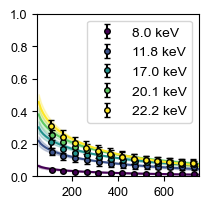

In [9]:
# Set font globally.
plt.rcParams['pdf.fonttype'] = 42  # Type 42 (TrueType), required for Adobe Illustrator.
plt.rcParams['ps.fonttype'] = 42   # Ensures fonts are saved as TrueType in EPS.
plt.rcParams['font.family'] = 'Arial'
params = {'mathtext.default': 'regular' }          
plt.rcParams.update(params)

# Colors corresponding to different energies.
# colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
colors = plt.get_cmap('viridis', n_energies)(np.arange(n_energies))

''' We are going to break up the dataset into
    the original two segments: one that showcases
    y-dependence, and one that showcases a-dependence. '''
# First: y-depdendent data.
fig, ax = plt.subplots(1, 1, figsize=(3, 3), sharex=True, sharey=True)
# Loop over energies.
for i in range(0, n_energies):
    # Plot the model fit.
    # We add 1 to the left edge of the y-range. This is because the model diverges when y <= a.
    a_fit = np.average(a_excitation[np.where(np.squeeze(w_slit) == 0.5)])
    y_fit = np.arange(a_fit+1, 750, 10)
    model_A, model_A_lower, model_A_upper = model_confidence_band(
        parameter_estimates[i,:],
        covariance_matrices[i,:,:],
        fit_dofs[i],
        y_fit,
        a_fit
    )
    ax.plot(y_fit, model_A, color=colors[i])
    ax.fill_between(y_fit, model_A_upper, model_A_lower, color=colors[i], alpha=0.25)
    # Plot the experimental data.
    # The slit width was fixed at 500 microns for all y-dependent experiments.
    I = np.where((np.squeeze(w_slit) == 0.5) & (np.squeeze(energy) == unique_energies[i]))
#     ax.scatter(np.squeeze(avg_y_µm[I]), np.squeeze(avg_pattern_signal[I]), color=colors[i])
    ax.errorbar(np.squeeze(avg_y_µm[I]), np.squeeze(avg_pattern_signal[I]),
                yerr=np.squeeze(std_pattern_signal[I]),
                fmt='o',
                ms=4,
                mec='k',
                color=colors[i],
                ecolor='k',
                capsize=2, label='{:.1f} keV'.format(unique_energies[i]))
    
    # Dress up the subplots.
#     ax.set_xlabel('y [µm]', fontsize=14)
#     ax.set_ylabel('Intensity (a.u.)', fontsize=14)
    ax.set_xlim([50, 750])
    ax.set_ylim([0, 1])
    ax.tick_params(axis='x', labelsize=9)
    ax.tick_params(axis='y', labelsize=9)
#     ax.set_title('w = {:.4f} in ({:.0f} µm)'.format(500/(25.4*1e3), 500))

plt.legend()
plt.tight_layout()
fig.set_size_inches(2, 2)
plt.show()

meta NOT subset; don't know how to subset; dropped


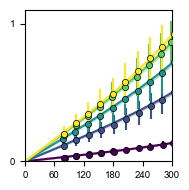

In [10]:
# Set font globally.
plt.rcParams['pdf.fonttype'] = 42  # Type 42 (TrueType), required for Adobe Illustrator.
plt.rcParams['ps.fonttype'] = 42   # Ensures fonts are saved as TrueType in EPS.
plt.rcParams['font.family'] = 'Arial'
params = {'mathtext.default': 'regular' }          
plt.rcParams.update(params)

# Colors corresponding to different patterns.
# colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
colors = plt.get_cmap('viridis', n_energies)(np.arange(n_energies))

''' We are going to break up the dataset into
    the original two segments: one that showcases
    y-dependence, and one that showcases a-dependence. '''
# Second: a-depdendent data.
fig, ax = plt.subplots(1, 1, figsize=(2, 2), sharex=True, sharey=True)
# Loop over energies.
for i in range(0, n_energies):
    # Plot the model fit.
    # Get the average y-position of the current pattern.
    y_fit = np.average(avg_y_µm[np.where(np.squeeze(w_slit) != 0.5)])
    # We add 1e-6 to the right edge of the y-range. This is because the model diverges when y <= a.
    a_fit = np.arange(0, y_fit+1, 10)
    model_A, model_A_lower, model_A_upper = model_confidence_band(
        parameter_estimates[i,:],
        covariance_matrices[i,:,:],
        fit_dofs[i],
        y_fit,
        a_fit
    )
    ax.plot(a_fit, model_A, color=colors[i])
    ax.fill_between(a_fit, model_A_upper, model_A_lower, color=colors[i], alpha=0.25)
    # Plot the experimental data.
    # The slit width was fixed at 500 microns for all y-dependent experiments.
    I = np.where((np.squeeze(w_slit) != 0.5) & (np.squeeze(energy) == unique_energies[i]))
#     ax.scatter(np.squeeze(a_excitation[I]), np.squeeze(avg_pattern_signal[I]), color=colors[i])
#     ax.errorbar(np.squeeze(a_excitation[I]), np.squeeze(avg_pattern_signal[I]),
#                 yerr=np.squeeze(std_pattern_signal[I]),
#                 fmt='o',
#                 ms=4,
#                 mec='k',
#                 color=colors[i],
#                 ecolor='k',
#                 capsize=2, label='{:.1f} keV'.format(unique_energies[i]))
    ax.errorbar(np.squeeze(a_excitation[I]), np.squeeze(avg_pattern_signal[I]),
                yerr=np.squeeze(std_pattern_signal[I]),
                fmt='none',
                ecolor=colors[i],
                capsize=0)
    ax.scatter(np.squeeze(a_excitation[I]), np.squeeze(avg_pattern_signal[I]), 20,
               facecolor=colors[i], linewidths=0.5, edgecolor='black', zorder=10,
               label='{:.1f} keV'.format(unique_energies[i]))

    # Dress up the subplots.
#     ax.set_xlabel('a [µm]', fontsize=7)
#     ax.set_ylabel('Intensity (a.u.)', fontsize=7)
    ax.set_xlim([0, 300])
    ax.set_ylim([0, 1.1])
    ax.set_xticks([0, 60, 120, 180, 240, 300])
    ax.set_yticks([0, 1])
    ax.tick_params(axis='x', labelsize=7)
    ax.tick_params(axis='y', labelsize=7)
#     ax.set_title('w = {:.4f} in ({:.0f} µm)'.format(500/(25.4*1e3), 500))

# plt.legend()
plt.tight_layout()
fig.set_size_inches(2, 2)
# plt.savefig("fig_3_yagce_synchrotron.pdf", format="pdf", bbox_inches='tight')
plt.savefig("fig_3_yagce_synchrotron_10-19-2026.pdf", format="pdf", bbox_inches='tight')
plt.show()

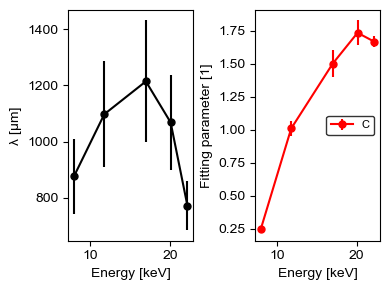

In [11]:
# Plot parameter estimates as a function of energy (with error bars).
fig, axes = plt.subplots(1, 2, sharex=True)

# Plot λ...
ax = axes[0]
ax.errorbar(
    unique_energies, parameter_estimates[:,0],
    yerr=parameter_errors[:,0], # Vertical error bars
    marker='o', color='black', markersize=5
    )
ax.set_xlabel('Energy [keV]')
ax.set_ylabel('λ [µm]')

# Plot C and D...
ax = axes[1]
ax.errorbar(
    unique_energies, parameter_estimates[:,1],
    yerr=parameter_errors[:,1], # Vertical error bars
    marker='o', color='red', markersize=5, label='C'
    )
ax.set_xlabel('Energy [keV]')
ax.set_ylabel('Fitting parameter [1]')
ax.legend(loc="center right",  fontsize=8, title_fontsize='small', frameon=True, facecolor='white', edgecolor='black')

# Adjust the size of the figure.
plt.tight_layout()
width, height = fig.get_size_inches()
aspect_ratio = 4/3
new_height = 3
new_width = new_height*aspect_ratio
fig.set_size_inches(new_width, new_height)

plt.tight_layout()
plt.show()

In [12]:
# Save fitting parameters.
# np.savez('fitting_parameters_yagce_synchrotron.npz', parameter_estimates, parameter_errors, unique_energies)
np.savez('fitting_parameters_yagce_synchrotron_10-19-2026.npz', parameter_estimates, parameter_errors, unique_energies)